# VaR of Equity Portfolio

**FINM 36700 · Group:** Lucas Albín Lazcano, Avi Rastogi, Mengting Wang, Yihan Kong

## Data

This problem uses `weekly` return data from `data/spx_returns_weekly.xlsx`.

Choose any `4` stocks to evaluate below.

For example, 
* `AAPL`
* `META`
* `NVDA`
* `TSLA`

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

INFILE = 'spx_returns_weekly.xlsx'
TICKS = ['AAPL', 'META', 'NVDA', 'TSLA']
FREQ = 52
Q = .05

rets = pd.read_excel(INFILE, sheet_name='spx returns').set_index('date')[TICKS]
print(f"{rets.index[0]:%Y-%m-%d} to {rets.index[-1]:%Y-%m-%d}, {len(rets)} weeks, missing values: {rets.isna().sum().sum()}")
rets.tail()

2015-07-10 to 2026-06-26, 573 weeks, missing values: 0


,AAPL,META,NVDA,TSLA
date,,,,
2026-05-29,0.010492,0.036459,-0.019459,0.022957
2026-06-05,-0.015125,-0.062465,-0.027474,-0.102779
2026-06-12,-0.052743,-0.043879,0.000439,0.039463
2026-06-19,0.023632,0.019004,0.026804,-0.014615
2026-06-26,-0.047750,-0.046724,-0.086193,-0.051886


# 1 Diversification

## 1.1

Using the full sample, calculate for each series the (unconditional) 
* volatility
* empirical VaR (.05)
* empirical CVaR (.05)

Recall that by **empirical** we refer to the direct quantile estimation. (For example, using `.quantile()` in pandas.

## 1.2
Form an equally-weighted portfolio of the investments.

Calculate the statistics of `1.1` for this portfolio, and compare the results to the individual return statistics. What do you find? What is driving this result?

## 1.3
Re-calculate `1.2`, but this time drop your most volatile asset, and replace the portion it was getting with 0. (You could imagine we're replacing the most volatile asset with a negligibly small risk-free rate.)

In comparing the answer here to 1.2, how much risk is your most volatile asset adding to the portfolio? Is this in line with the amount of risk we measured in the stand-alone risk-assessment of `1.1`?

### 1.1

In [2]:
def risk_stats(rets, q=Q, freq=FREQ):
    rets = pd.DataFrame(rets)
    var = rets.quantile(q)
    cvar = rets[rets <= var].mean()
    return pd.DataFrame({'Vol (ann.)': rets.std() * np.sqrt(freq),
                         f'VaR ({q})': var,
                         f'CVaR ({q})': cvar})

FMT = '{:.2%}'
stats = risk_stats(rets)
stats.style.format(FMT)

,Vol (ann.),VaR (0.05),CVaR (0.05)
AAPL,27.76%,-5.49%,-8.30%
META,35.75%,-7.23%,-10.64%
NVDA,45.44%,-8.58%,-11.53%
TSLA,57.97%,-11.70%,-14.78%


### 1.2

In [3]:
rets['EW'] = rets[TICKS].mean(axis=1)

stats = risk_stats(rets)
display(stats.style.format(FMT))
print(f"Average of individual stats:\n{stats.loc[TICKS].mean().map(FMT.format).to_string()}")

,Vol (ann.),VaR (0.05),CVaR (0.05)
AAPL,27.76%,-5.49%,-8.30%
META,35.75%,-7.23%,-10.64%
NVDA,45.44%,-8.58%,-11.53%
TSLA,57.97%,-11.70%,-14.78%
EW,31.20%,-6.07%,-8.42%


Average of individual stats:
Vol (ann.)      41.73%
VaR (0.05)      -8.25%
CVaR (0.05)    -11.31%


In [4]:
rets[TICKS].corr().style.format('{:.2f}')

,AAPL,META,NVDA,TSLA
AAPL,1.00,0.41,0.48,0.44
META,0.41,1.00,0.43,0.26
NVDA,0.48,0.43,1.00,0.41
TSLA,0.44,0.26,0.41,1.00


**Comments**

The equally-weighted portfolio is less risky than the average of its parts on every measure. Its volatility (~31%) is clearly below the average stand-alone volatility (~42%), and its VaR and CVaR are also milder than the average individual VaR/CVaR. Only `AAPL`, the least volatile stock, is safer than the portfolio.

This is **diversification**. Portfolio variance depends on the covariances, not only on the individual variances. The pairwise correlations here are only moderate (~0.26–0.48), so some of the idiosyncratic swings cancel each other out. Because these four stocks are all large-cap tech/growth names with positive correlations, the benefit is limited: the portfolio is still much riskier than the broad market.

### 1.3

In [5]:
most_vol = rets[TICKS].std().idxmax()
print(f'Most volatile asset: {most_vol}')

w = pd.Series(1 / len(TICKS), index=TICKS)
w[most_vol] = 0
rets[f'EW ex {most_vol}'] = rets[TICKS] @ w

stats = risk_stats(rets)
display(stats.style.format(FMT))

ew, ex = stats.loc['EW'], stats.loc[f'EW ex {most_vol}']
pd.DataFrame({'Change from removing': ew - ex, 'Share of EW risk': (ew - ex) / ew}).style.format(FMT)

Most volatile asset: TSLA


,Vol (ann.),VaR (0.05),CVaR (0.05)
AAPL,27.76%,-5.49%,-8.30%
META,35.75%,-7.23%,-10.64%
NVDA,45.44%,-8.58%,-11.53%
TSLA,57.97%,-11.70%,-14.78%
EW,31.20%,-6.07%,-8.42%
EW ex TSLA,21.69%,-4.23%,-6.00%


,Change from removing,Share of EW risk
Vol (ann.),9.51%,30.49%
VaR (0.05),-1.84%,30.36%
CVaR (0.05),-2.42%,28.72%


**Comments**

`TSLA` is the most volatile asset (~58% annualized vol, with the worst VaR and CVaR). Setting its 25% weight to zero cuts portfolio volatility from about 31% to about 22%, and reduces VaR and CVaR by a similar share. So `TSLA` accounts for roughly **30%** of the portfolio's risk.

Compare this with the stand-alone view from `1.1`. `TSLA`'s vol is about 35% of the sum of the four stand-alone vols (58 / 167), and its 0.25 × 58% ≈ 14.5% weighted vol would be almost half of the portfolio's 31% vol. In practice, removing it lowers vol by only about 9.5 percentage points (~30%). So `TSLA` adds a lot of risk, but **less than its stand-alone numbers suggest**. A stock's contribution to risk depends on its covariance with the rest of the portfolio, not only on its own volatility. `TSLA` has the lowest correlations with the others (e.g. 0.26 with `META`), so part of its stand-alone risk is idiosyncratic and gets diversified away. Note also that we replaced `TSLA` with cash rather than re-weighting the other stocks, so part of the reduction just comes from holding 75% in risky assets instead of 100%.

***

# 2. Dynamic Measures

## 2.1 

Let's measure the **conditional** statistics of the equally-weighted portfolio of `1.2`, as of the end of the sample.

#### Volatility
For each security, calculate the **rolling** volatility series, $\sigma_t$, with a window of $m=26$.

The value at $\sigma_t$ in the notes denotes the estimate using data through time $t-1$, and thus (potentially) predicting the volatility at $\sigma_{t}$. 

#### Mean
Suppose we can approximate that the weekly mean return is zero.

#### VaR
Calculate the **normal VaR** and **normal CVaR** for $q=.05$ and $\tau=1$ as of the end of the sample. Use the approximation, $\texttt{z}_{.05} = -1.65$.

#### Notation Note
In this setup, we are using a forecasted volatility, $\sigma_t$ to estimate the VaR return we would have estimated at the end of $t-1$ in prediction of time $t$.

#### Conclude and Compare
Report
* volatility (annualized).
* normal VaR (.05)
* normal CVaR (.05)

How do these compare to the answers in `1.2`?

### 2.1

With a zero-mean assumption, the volatility estimators are

$$\sigma^2_{t,\text{rolling}} = \frac{1}{m}\sum_{i=1}^{m} r^2_{t-i}, \qquad \sigma^2_{t,\text{expanding}} = \frac{1}{t-1}\sum_{i=1}^{t-1} r^2_{i}$$

Both use data only through $t-1$, so we `shift(1)` them to align $\sigma_t$ with the return at $t$. For the expanding estimator we require at least $m=26$ observations, so both series start on the same date.

Normal VaR and CVaR with zero mean:

$$\text{VaR}_t = \texttt{z}_{.05}\,\sigma_t, \qquad \text{CVaR}_t = -\frac{\phi(\texttt{z}_{.05})}{q}\,\sigma_t$$

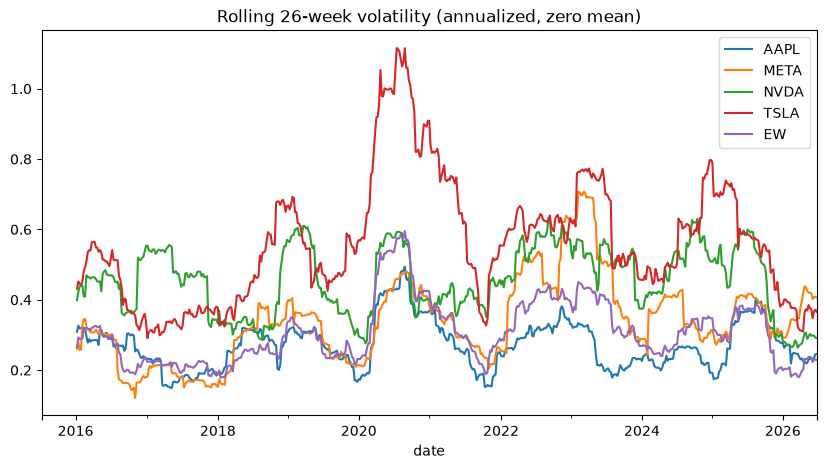

In [6]:
M_WINDOW = 26
Z = -1.65
PORT = 'EW'
assets = TICKS + [PORT]

# sigma_t uses data through t-1
vol_roll = np.sqrt((rets[assets]**2).rolling(M_WINDOW).mean().shift(1))
vol_exp = np.sqrt((rets[assets]**2).expanding(M_WINDOW).mean().shift(1))

vol_roll.mul(np.sqrt(FREQ)).plot(figsize=(10, 5), title=f'Rolling {M_WINDOW}-week volatility (annualized, zero mean)')
plt.show()

"As of the end of the sample" means the forecast for the week after the last observation, so $\sigma$ uses the final 26 weeks of data (through the last date).

In [7]:
def normal_var_cvar(sigma, z=Z, q=Q):
    return z * sigma, -norm.pdf(z) / q * sigma

sig_end = np.sqrt((rets[assets].iloc[-M_WINDOW:]**2).mean())
var_end, cvar_end = normal_var_cvar(sig_end)

cond = pd.DataFrame({'Vol (ann.)': sig_end * np.sqrt(FREQ),
                     f'Normal VaR ({Q})': var_end,
                     f'Normal CVaR ({Q})': cvar_end})
print(f'Conditional stats as of {rets.index[-1]:%Y-%m-%d}')
display(cond.style.format(FMT))

compare = pd.DataFrame({
    'Unconditional (1.2)': risk_stats(rets[PORT]).loc[PORT].values,
    'Conditional (2.1)': cond.loc[PORT].values,
}, index=['Vol (ann.)', 'VaR (.05)', 'CVaR (.05)'])
print(f'Equally-weighted portfolio')
compare.style.format(FMT)

Conditional stats as of 2026-06-26


,Vol (ann.),Normal VaR (0.05),Normal CVaR (0.05)
AAPL,25.53%,-5.84%,-7.24%
META,41.24%,-9.44%,-11.70%
NVDA,30.65%,-7.01%,-8.69%
TSLA,37.26%,-8.53%,-10.57%
EW,24.23%,-5.55%,-6.87%


Equally-weighted portfolio


,Unconditional (1.2),Conditional (2.1)
Vol (ann.),31.20%,24.23%
VaR (.05),-6.07%,-5.55%
CVaR (.05),-8.42%,-6.87%


**Comments**

As of the end of the sample, the rolling estimate of the EW portfolio's volatility (~24% annualized) is clearly **below** the full-sample unconditional vol from `1.2` (~31%). The normal VaR and CVaR are correspondingly milder than the unconditional numbers (VaR ~ -5.5% vs. -6.1%). The normal CVaR (~ -6.9%) is also less severe than the empirical CVaR (~ -8.4%).

So the last six months have been a relatively calm period for these stocks compared with the full 2015–2026 history. The conditional numbers adjust to the current regime, while the unconditional ones average over very different periods (e.g. 2020, 2022). Keep in mind that the normal approximation ignores fat tails, so the normal CVaR in particular probably understates tail losses.

## 2.2

Backtest the VaR using the **hit test**. Namely, check how many times the realized return at $t$ was smaller than the VaR return calculated using $\sigma_t$, (where again remember the notation in the notes uses $\sigma_t$ as a vol based on data through $t-1$.)

Report the percentage of "hits" using both the 
* expanding volatility
* rolling volatility

In [8]:
var_roll = Z * vol_roll[PORT]
var_exp = Z * vol_exp[PORT]

hits = {}
for name, var_series in {'Expanding': var_exp, 'Rolling': var_roll}.items():
    valid = var_series.notna()
    hit = rets.loc[valid, PORT] < var_series[valid]
    hits[name] = {'Hits': hit.sum(), 'Observations': valid.sum(), 'Hit rate': hit.mean()}

hits = pd.DataFrame(hits).T
hits['Target'] = Q
hits.style.format({'Hits': '{:.0f}', 'Observations': '{:.0f}', 'Hit rate': FMT, 'Target': FMT})

,Hits,Observations,Hit rate,Target
Expanding,22,547,4.02%,5.00%
Rolling,21,547,3.84%,5.00%


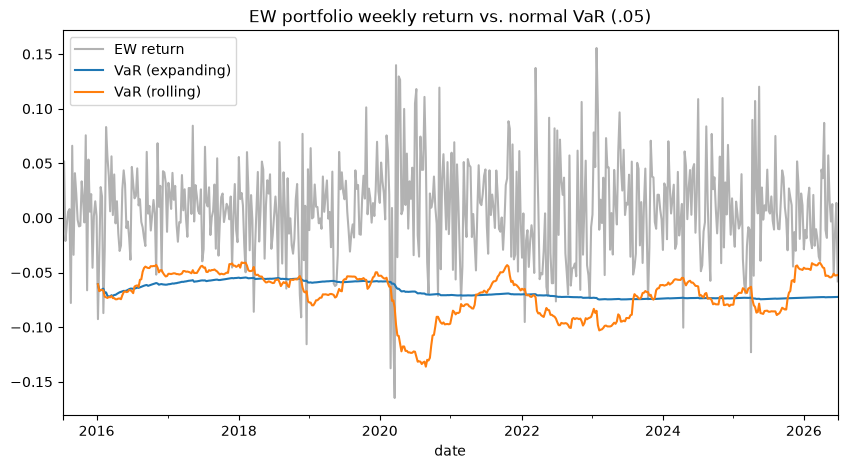

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))
rets[PORT].plot(ax=ax, color='gray', alpha=.6, label='EW return')
var_exp.plot(ax=ax, label='VaR (expanding)')
var_roll.plot(ax=ax, label='VaR (rolling)')
ax.set_title('EW portfolio weekly return vs. normal VaR (.05)')
ax.legend()
plt.show()

**Answer**

Both estimators give a hit rate a little **below** the 5% target (~4.0% for expanding, ~3.8% for rolling), so the normal VaR with $\texttt{z}=-1.65$ is slightly conservative on average.

Two things push the hit rate down. First, the zero-mean assumption: the portfolio's average weekly return is clearly positive, so a zero-mean VaR sits a little too low. Second, using $\sum r^2$ around zero instead of around the mean slightly overstates volatility.

The two methods behave differently over time. The expanding VaR moves very slowly, so it does not respond to changes in the volatility regime: its hits tend to bunch up in high-volatility episodes (see the plot, e.g. 2020 and 2022), and it is too conservative in calm periods. The rolling VaR follows changes in volatility, so it tightens in calm periods and widens in turbulent ones. On the other side, a 26-week window reacts to volatility spikes only after a lag, and the normal distribution understates fat tails. Both of these push the hit rate up, partly offsetting the effects above. Overall, the rolling estimator is the better conditional risk measure, even though the average hit rates are similar.